<a href="https://colab.research.google.com/github/SparshM07/SPARSH_MAURA_MLE_CASE_STUDY-3/blob/main/Case_Study_3_Sentiment_Analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip install -q transformers datasets accelerate evaluate scikit-learn pandas numpy matplotlib seaborn torch

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import torch
import time

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

print("PyTorch version:", torch.__version__)
print("GPU available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

PyTorch version: 2.11.0+cu130
GPU available: True
GPU: Tesla T4


In [ ]:
import pandas as pd

df = pd.read_csv(
    '/content/Reviews.csv',
    engine='python',
    on_bad_lines='warn',
    encoding='utf-8'
)

print("Dataset shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())

df.head()

Dataset shape: (568454, 10)

Columns:
['Id', 'ProductId', 'UserId', 'ProfileName', 'HelpfulnessNumerator', 'HelpfulnessDenominator', 'Score', 'Time', 'Summary', 'Text']


,Id,ProductId,UserId,ProfileName,HelpfulnessNumerator,HelpfulnessDenominator,Score,Time,Summary,Text
0,1,B001E4KFG0,A3SGXH7AUHU8GW,delmartian,1,1,5,1303862400,Good Quality Dog Food,I have bought several of the Vitality canned d...
1,2,B00813GRG4,A1D87F6ZCVE5NK,dll pa,0,0,1,1346976000,Not as Advertised,Product arrived labeled as Jumbo Salted Peanut...
2,3,B000LQOCH0,ABXLMWJIXXAIN,"Natalia Corres ""Natalia Corres""",1,1,4,1219017600,"""Delight"" says it all",This is a confection that has been around a fe...
3,4,B000UA0QIQ,A395BORC6FGVXV,Karl,3,3,2,1307923200,Cough Medicine,If you are looking for the secret ingredient i...
4,5,B006K2ZZ7K,A1UQRSCLF8GW1T,"Michael D. Bigham ""M. Wassir""",0,0,5,1350777600,Great taffy,Great taffy at a great price. There was a wid...


In [ ]:
print("Total reviews:", len(df))
print("\nMissing values:")
print(df[['Text', 'Score']].isnull().sum())

print("\nRating distribution:")
print(df['Score'].value_counts().sort_index())

Total reviews: 568454

Missing values:
Text     0
Score    0
dtype: int64

Rating distribution:
Score
1     52268
2     29769
3     42640
4     80655
5    363122
Name: count, dtype: int64


In [ ]:
def get_sentiment(score):
    if score <= 2:
        return "Negative"
    elif score == 3:
        return "Neutral"
    else:
        return "Positive"

df['Sentiment'] = df['Score'].apply(get_sentiment)

print("Sentiment distribution:")
print(df['Sentiment'].value_counts())

print("\nSample reviews:")
display(df[['Text', 'Score', 'Sentiment']].head(10))

Sentiment distribution:
Sentiment
Positive    443777
Negative     82037
Neutral      42640
Name: count, dtype: int64

Sample reviews:


,Text,Score,Sentiment
0,I have bought several of the Vitality canned d...,5,Positive
1,Product arrived labeled as Jumbo Salted Peanut...,1,Negative
2,This is a confection that has been around a fe...,4,Positive
3,If you are looking for the secret ingredient i...,2,Negative
4,Great taffy at a great price. There was a wid...,5,Positive
5,I got a wild hair for taffy and ordered this f...,4,Positive
6,This saltwater taffy had great flavors and was...,5,Positive
7,This taffy is so good. It is very soft and ch...,5,Positive
8,Right now I'm mostly just sprouting this so my...,5,Positive
9,This is a very healthy dog food. Good for thei...,5,Positive


In [ ]:
sentiment_mapping = {
    "Negative": 0,
    "Neutral": 1,
    "Positive": 2
}

df['Label'] = df['Sentiment'].map(sentiment_mapping)

print(df[['Text', 'Score', 'Sentiment', 'Label']].head())

                                                Text  Score Sentiment  Label
0  I have bought several of the Vitality canned d...      5  Positive      2
1  Product arrived labeled as Jumbo Salted Peanut...      1  Negative      0
2  This is a confection that has been around a fe...      4  Positive      2
3  If you are looking for the secret ingredient i...      2  Negative      0
4  Great taffy at a great price.  There was a wid...      5  Positive      2


In [ ]:
df = df[['Text', 'Sentiment', 'Label']].copy()

df.drop_duplicates(subset=['Text'], inplace=True)
df.dropna(subset=['Text', 'Label'], inplace=True)

df = df.reset_index(drop=True)

print("Final dataset shape:", df.shape)
print("\nFinal sentiment distribution:")
print(df['Sentiment'].value_counts())

Final dataset shape: (393579, 3)

Final sentiment distribution:
Sentiment
Positive    306758
Negative     57067
Neutral      29754
Name: count, dtype: int64


In [ ]:
from sklearn.model_selection import train_test_split

df_fast, _ = train_test_split(
    df,
    train_size=5000,
    stratify=df['Label'],
    random_state=42
)

X_train, X_test, y_train, y_test = train_test_split(
    df_fast['Text'],
    df_fast['Label'],
    test_size=0.2,
    stratify=df_fast['Label'],
    random_state=42
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 4000
Testing samples: 1000


In [ ]:
from transformers import AutoTokenizer

MODEL_NAME = "bert-base-uncased"

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

print("BERT tokenizer loaded successfully!")

BERT tokenizer loaded successfully!


In [ ]:
MAX_LENGTH = 96

train_encodings = tokenizer(
    X_train.tolist(),
    truncation=True,
    padding="max_length",
    max_length=MAX_LENGTH
)

test_encodings = tokenizer(
    X_test.tolist(),
    truncation=True,
    padding="max_length",
    max_length=MAX_LENGTH
)

In [ ]:
from transformers import AutoModelForSequenceClassification

model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels=3
)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model.to(device)

print("BERT model loaded successfully!")
print("Device:", device)

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


BERT model loaded successfully!
Device: cuda


In [ ]:
from torch.utils.data import Dataset, DataLoader

class ReviewDataset(Dataset):

    def __init__(self, encodings, labels):
        self.encodings = encodings
        self.labels = list(labels)

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, idx):
        return {
            'input_ids': torch.tensor(self.encodings['input_ids'][idx]),
            'attention_mask': torch.tensor(self.encodings['attention_mask'][idx]),
            'labels': torch.tensor(self.labels[idx], dtype=torch.long)
        }

train_dataset = ReviewDataset(train_encodings, y_train)
test_dataset = ReviewDataset(test_encodings, y_test)

train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=64)

print("Training batches:", len(train_loader))
print("Testing batches:", len(test_loader))

Training batches: 125
Testing batches: 16


In [ ]:
from torch.optim import AdamW
from tqdm.auto import tqdm
import time
import torch

optimizer = AdamW(model.parameters(), lr=2e-5)

EPOCHS = 5

epoch_losses = []
start_time = time.time()

for epoch in range(EPOCHS):

    model.train()
    total_loss = 0

    progress_bar = tqdm(
        train_loader,
        desc=f"Epoch {epoch+1}/{EPOCHS}"
    )

    for batch in progress_bar:

        input_ids = batch['input_ids'].to(device)
        attention_mask = batch['attention_mask'].to(device)
        labels = batch['labels'].to(device)

        optimizer.zero_grad()

        with torch.autocast(
            device_type="cuda",
            dtype=torch.float16,
            enabled=torch.cuda.is_available()
        ):

            outputs = model(
                input_ids=input_ids,
                attention_mask=attention_mask,
                labels=labels
            )

            loss = outputs.loss

        loss.backward()
        optimizer.step()

        total_loss += loss.item()

        progress_bar.set_postfix(loss=loss.item())

    avg_loss = total_loss / len(train_loader)
    epoch_losses.append(avg_loss)

    print(f"Epoch {epoch+1} Average Loss: {avg_loss:.4f}")

training_time = time.time() - start_time

print("\nBERT training completed!")
print("Total training time:", round(training_time, 2), "seconds")

Epoch 1/5:   0%|          | 0/125 [00:00<?, ?it/s]

Epoch 1 Average Loss: 0.2398


Epoch 2/5:   0%|          | 0/125 [00:00<?, ?it/s]

Epoch 2 Average Loss: 0.1483


Epoch 3/5:   0%|          | 0/125 [00:00<?, ?it/s]

Epoch 3 Average Loss: 0.1091


Epoch 4/5:   0%|          | 0/125 [00:00<?, ?it/s]

Epoch 4 Average Loss: 0.0605


Epoch 5/5:   0%|          | 0/125 [00:00<?, ?it/s]

Epoch 5 Average Loss: 0.0378

BERT training completed!
Total training time: 98.34 seconds


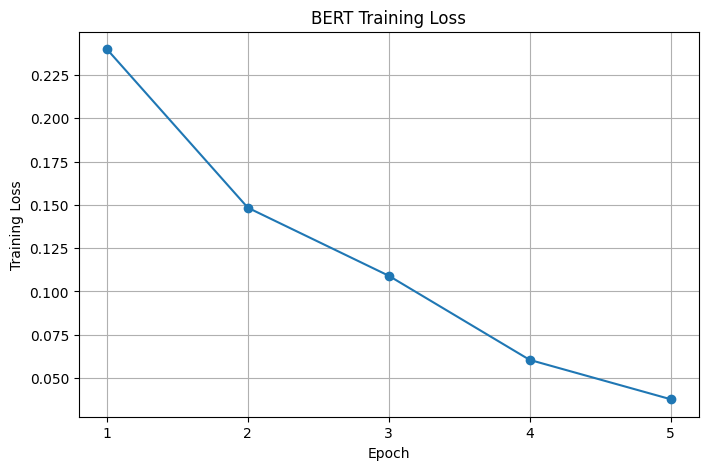

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.plot(
    range(1, EPOCHS + 1),
    epoch_losses,
    marker='o'
)

plt.xlabel("Epoch")
plt.ylabel("Training Loss")
plt.title("BERT Training Loss")
plt.xticks(range(1, EPOCHS + 1))
plt.grid(True)
plt.show()

In [ ]:
model.save_pretrained("/content/bert_sentiment_model")
tokenizer.save_pretrained("/content/bert_sentiment_model")

print("BERT model saved successfully!")

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

BERT model saved successfully!


In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

model.eval()

all_predictions = []
all_labels = []

start_eval = time.time()

with torch.no_grad():

    for batch in tqdm(test_loader, desc="Evaluating BERT"):

        input_ids = batch['input_ids'].to(device)
        attention_mask = batch['attention_mask'].to(device)

        outputs = model(
            input_ids=input_ids,
            attention_mask=attention_mask
        )

        predictions = torch.argmax(outputs.logits, dim=1)

        all_predictions.extend(predictions.cpu().numpy())
        all_labels.extend(batch['labels'].numpy())

bert_eval_time = time.time() - start_eval

print("BERT Accuracy:", accuracy_score(all_labels, all_predictions))
print("BERT Precision:", precision_score(all_labels, all_predictions, average='weighted'))
print("BERT Recall:", recall_score(all_labels, all_predictions, average='weighted'))
print("BERT F1 Score:", f1_score(all_labels, all_predictions, average='weighted'))

print("\nClassification Report:")
print(classification_report(
    all_labels,
    all_predictions,
    target_names=["Negative", "Neutral", "Positive"]
))

print("Evaluation time:", round(bert_eval_time, 2), "seconds")

Evaluating BERT:   0%|          | 0/16 [00:00<?, ?it/s]

BERT Accuracy: 0.843
BERT Precision: 0.8581515642173285
BERT Recall: 0.843
BERT F1 Score: 0.847027213714192

Classification Report:
              precision    recall  f1-score   support

    Negative       0.76      0.54      0.63       145
     Neutral       0.30      0.43      0.35        76
    Positive       0.93      0.94      0.93       779

    accuracy                           0.84      1000
   macro avg       0.66      0.64      0.64      1000
weighted avg       0.86      0.84      0.85      1000

Evaluation time: 5.43 seconds


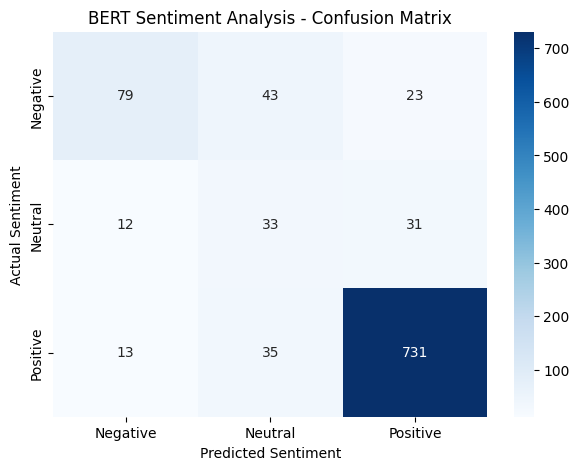

In [ ]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

cm = confusion_matrix(all_labels, all_predictions)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Negative', 'Neutral', 'Positive'],
    yticklabels=['Negative', 'Neutral', 'Positive']
)

plt.xlabel("Predicted Sentiment")
plt.ylabel("Actual Sentiment")
plt.title("BERT Sentiment Analysis - Confusion Matrix")
plt.show()

In [ ]:
import re
from collections import Counter

MAX_VOCAB = 20000
MAX_LEN = 96

def tokenize_text(text):
    return re.findall(r'\b\w+\b', text.lower())

# Build vocabulary using training reviews only
word_counts = Counter()

for review in X_train:
    word_counts.update(tokenize_text(review))

vocab = {
    word: idx + 2
    for idx, (word, count) in enumerate(word_counts.most_common(MAX_VOCAB))
}

vocab["<PAD>"] = 0
vocab["<UNK>"] = 1

print("Vocabulary size:", len(vocab))

Vocabulary size: 13656


In [ ]:
def encode_reviews(reviews):
    sequences = []

    for review in reviews:
        tokens = tokenize_text(review)
        sequence = [vocab.get(word, 1) for word in tokens[:MAX_LEN]]

        sequence += [0] * (MAX_LEN - len(sequence))

        sequences.append(sequence)

    return torch.tensor(sequences, dtype=torch.long)

X_train_lstm = encode_reviews(X_train)
X_test_lstm = encode_reviews(X_test)

y_train_lstm = torch.tensor(y_train.to_numpy(), dtype=torch.long)
y_test_lstm = torch.tensor(y_test.to_numpy(), dtype=torch.long)

print("Training shape:", X_train_lstm.shape)
print("Testing shape:", X_test_lstm.shape)

Training shape: torch.Size([4000, 96])
Testing shape: torch.Size([1000, 96])


In [ ]:
from torch.utils.data import TensorDataset, DataLoader

train_lstm_dataset = TensorDataset(X_train_lstm, y_train_lstm)
test_lstm_dataset = TensorDataset(X_test_lstm, y_test_lstm)

train_lstm_loader = DataLoader(
    train_lstm_dataset,
    batch_size=64,
    shuffle=True
)

test_lstm_loader = DataLoader(
    test_lstm_dataset,
    batch_size=128,
    shuffle=False
)

print("LSTM training batches:", len(train_lstm_loader))
print("LSTM testing batches:", len(test_lstm_loader))

LSTM training batches: 63
LSTM testing batches: 8


In [ ]:
import torch.nn as nn

class LSTMSentiment(nn.Module):

    def __init__(self, vocab_size, embedding_dim=128,
                 hidden_dim=128, num_classes=3):

        super(LSTMSentiment, self).__init__()

        self.embedding = nn.Embedding(
            vocab_size, embedding_dim, padding_idx=0
        )

        self.lstm = nn.LSTM(
            embedding_dim,
            hidden_dim,
            batch_first=True,
            bidirectional=True
        )

        self.dropout = nn.Dropout(0.3)

        self.fc = nn.Linear(hidden_dim * 2, num_classes)

    def forward(self, x):

        embedded = self.embedding(x)

        _, (hidden, _) = self.lstm(embedded)

        hidden_forward = hidden[-2]
        hidden_backward = hidden[-1]

        combined = torch.cat(
            (hidden_forward, hidden_backward), dim=1
        )

        combined = self.dropout(combined)

        return self.fc(combined)


lstm_model = LSTMSentiment(
    vocab_size=len(vocab)
).to(device)

print(lstm_model)

LSTMSentiment(
  (embedding): Embedding(13656, 128, padding_idx=0)
  (lstm): LSTM(128, 128, batch_first=True, bidirectional=True)
  (dropout): Dropout(p=0.3, inplace=False)
  (fc): Linear(in_features=256, out_features=3, bias=True)
)


In [ ]:
import torch.optim as optim
from tqdm.auto import tqdm
import time

criterion = nn.CrossEntropyLoss()

optimizer_lstm = optim.Adam(
    lstm_model.parameters(),
    lr=0.001
)

EPOCHS = 5
lstm_losses = []

start_time = time.time()

for epoch in range(EPOCHS):

    lstm_model.train()
    total_loss = 0

    for reviews, labels in tqdm(
        train_lstm_loader,
        desc=f"Epoch {epoch+1}/{EPOCHS}"
    ):

        reviews = reviews.to(device)
        labels = labels.to(device)

        optimizer_lstm.zero_grad()

        outputs = lstm_model(reviews)

        loss = criterion(outputs, labels)

        loss.backward()
        optimizer_lstm.step()

        total_loss += loss.item()

    avg_loss = total_loss / len(train_lstm_loader)
    lstm_losses.append(avg_loss)

    print(f"Epoch {epoch+1} Loss: {avg_loss:.4f}")

lstm_training_time = time.time() - start_time

print("\nLSTM training completed!")
print("Training time:", round(lstm_training_time, 2), "seconds")

Epoch 1/5:   0%|          | 0/63 [00:00<?, ?it/s]

Epoch 1 Loss: 0.7274


Epoch 2/5:   0%|          | 0/63 [00:00<?, ?it/s]

Epoch 2 Loss: 0.6083


Epoch 3/5:   0%|          | 0/63 [00:00<?, ?it/s]

Epoch 3 Loss: 0.5363


Epoch 4/5:   0%|          | 0/63 [00:00<?, ?it/s]

Epoch 4 Loss: 0.4447


Epoch 5/5:   0%|          | 0/63 [00:00<?, ?it/s]

Epoch 5 Loss: 0.3464

LSTM training completed!
Training time: 4.79 seconds


In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

lstm_model.eval()

lstm_predictions = []
lstm_actual = []

start_eval = time.time()

with torch.no_grad():

    for reviews, labels in test_lstm_loader:

        reviews = reviews.to(device)

        outputs = lstm_model(reviews)

        predictions = torch.argmax(outputs, dim=1)

        lstm_predictions.extend(predictions.cpu().numpy())
        lstm_actual.extend(labels.numpy())

lstm_eval_time = time.time() - start_eval

print("LSTM Accuracy:",
      accuracy_score(lstm_actual, lstm_predictions))

print("LSTM Precision:",
      precision_score(lstm_actual, lstm_predictions, average='weighted'))

print("LSTM Recall:",
      recall_score(lstm_actual, lstm_predictions, average='weighted'))

print("LSTM F1 Score:",
      f1_score(lstm_actual, lstm_predictions, average='weighted'))

print("\nClassification Report:")

print(classification_report(
    lstm_actual,
    lstm_predictions,
    target_names=["Negative", "Neutral", "Positive"]
))

print("Evaluation time:", round(lstm_eval_time, 2), "seconds")

LSTM Accuracy: 0.75
LSTM Precision: 0.7178285046803236
LSTM Recall: 0.75
LSTM F1 Score: 0.7315489671954081

Classification Report:
              precision    recall  f1-score   support

    Negative       0.37      0.45      0.40       145
     Neutral       0.07      0.01      0.02        76
    Positive       0.85      0.88      0.86       779

    accuracy                           0.75      1000
   macro avg       0.43      0.45      0.43      1000
weighted avg       0.72      0.75      0.73      1000

Evaluation time: 0.09 seconds


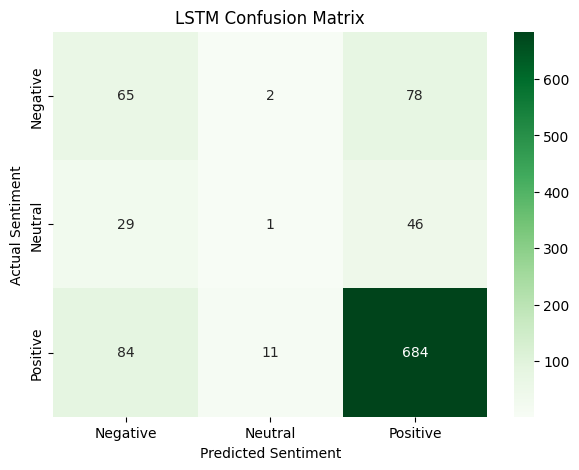

In [ ]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

cm_lstm = confusion_matrix(lstm_actual, lstm_predictions)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm_lstm,
    annot=True,
    fmt='d',
    cmap='Greens',
    xticklabels=['Negative', 'Neutral', 'Positive'],
    yticklabels=['Negative', 'Neutral', 'Positive']
)

plt.xlabel("Predicted Sentiment")
plt.ylabel("Actual Sentiment")
plt.title("LSTM Confusion Matrix")
plt.show()

In [ ]:
print("BERT Training Time:", round(training_time, 2), "seconds")
print("LSTM Training Time:", round(lstm_training_time, 2), "seconds")

BERT Training Time: 98.34 seconds
LSTM Training Time: 4.79 seconds
